# PCA 降维信息保留分析

分析距离向量数据经 PCA 降维后保留的信息百分比（解释方差比）。

In [1]:
# ==================== 导入与配置 ====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import ast

plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False


class StandardThenMinMaxScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.ss = StandardScaler(); self.mm = MinMaxScaler()
    def fit(self, X, y=None):
        self.ss.fit(X); self.mm.fit(self.ss.transform(X)); return self
    def transform(self, X):
        return self.mm.transform(self.ss.transform(X))
    def inverse_transform(self, X):
        return self.ss.inverse_transform(self.mm.inverse_transform(X))

# ==================== 数据加载辅助函数 ====================
def load_distance_vectors(filepath):
    """加载 .pkl 文件中的距离向量，返回 (X, name)"""
    df = pd.read_pickle(filepath)
    dist_col = df['distance_vector_to_grids']
    first_val = dist_col.iloc[0]
    if isinstance(first_val, str):
        X = np.array([ast.literal_eval(s) for s in dist_col]).astype(np.float64)
    else:
        X = np.array(dist_col.tolist()).astype(np.float64)
    name = filepath.split('\\')[-1].replace('.pkl', '')
    return X, name

# ==================== 加载两个数据文件 ====================
BASE = r'c:\KAN-OLS-SHF\output\model\mesh'
FILES = [
    BASE + r'\shf_with_distance_vectors.pkl',
    BASE + r'\shf_with_distance_vectors_normal.pkl',
]

datasets = {}
for fp in FILES:
    X, name = load_distance_vectors(fp)
    datasets[name] = X
    print(f'📂 {name}: shape={X.shape}, range=[{X.min():.4f}, {X.max():.4f}]')

📂 shf_with_distance_vectors: shape=(703, 625), range=[0.0059, 16.9603]
📂 shf_with_distance_vectors_normal: shape=(703, 4131), range=[0.0000, 18.0193]


## 1. 标准化 + 完整 PCA 拟合


📊 shf_with_distance_vectors
  原始特征数: 625, 样本数: 703 → PCA 可计算 625 个成分
  前   1 PC 累计方差:  53.97%
  前   2 PC 累计方差:  87.59%
  前   3 PC 累计方差:  97.92%
  前   5 PC 累计方差:  99.11%
  前   8 PC 累计方差:  99.73%
  前  10 PC 累计方差:  99.84%
  前  15 PC 累计方差:  99.94%
  前  20 PC 累计方差:  99.97%
  前  30 PC 累计方差:  99.99%
  前  50 PC 累计方差: 100.00%
  前 100 PC 累计方差: 100.00%
  ──────────────────────────────────────────────────
  🎯 PCA → 20 维保留信息: 99.97%
  📉 信息损失: 0.03%

📊 shf_with_distance_vectors_normal
  原始特征数: 4131, 样本数: 703 → PCA 可计算 703 个成分
  前   1 PC 累计方差:  59.57%
  前   2 PC 累计方差:  84.97%
  前   3 PC 累计方差:  98.04%
  前   5 PC 累计方差:  99.17%
  前   8 PC 累计方差:  99.75%
  前  10 PC 累计方差:  99.85%
  前  15 PC 累计方差:  99.94%
  前  20 PC 累计方差:  99.97%
  前  30 PC 累计方差:  99.99%
  前  50 PC 累计方差: 100.00%
  前 100 PC 累计方差: 100.00%
  ──────────────────────────────────────────────────
  🎯 PCA → 20 维保留信息: 99.97%
  📉 信息损失: 0.03%

🏁 对比总结: PCA → 20 维
  shf_with_distance_vectors                    : 保留  99.97%  (损失 0.03%)
  shf_with_distanc

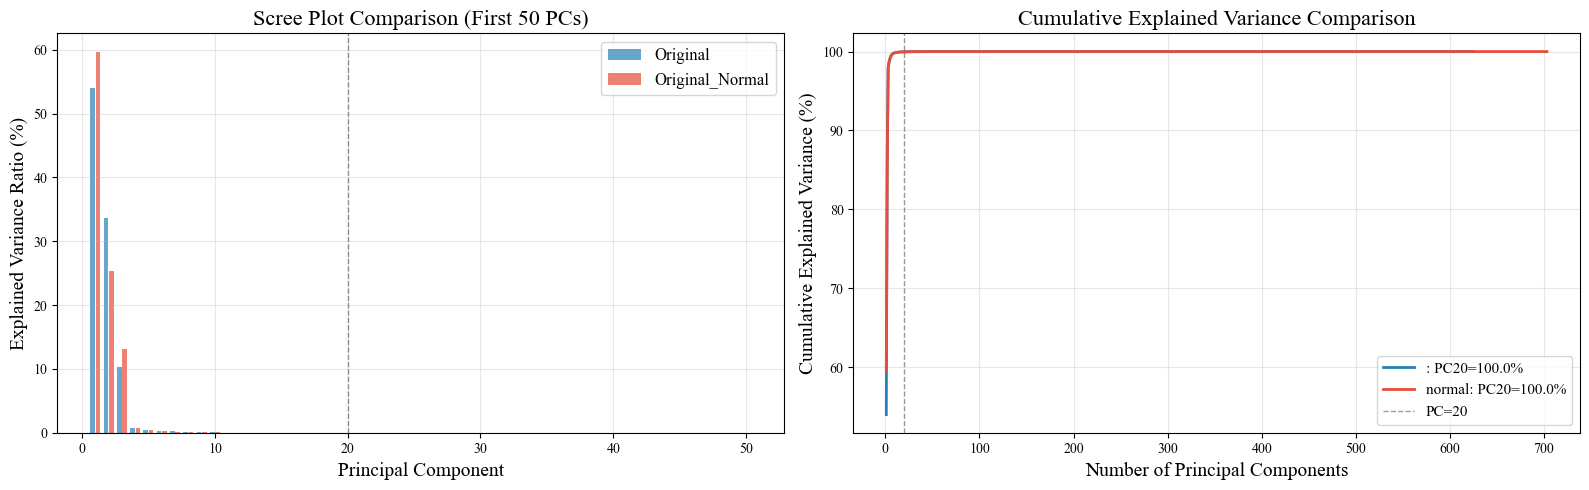

In [2]:
# ==================== 对比 PCA：两个数据集分别降至 20 维 ====================
PC_TARGET = 20
results = {}

for name, X in datasets.items():
    scaler = StandardThenMinMaxScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca_full = PCA()
    pca_full.fit(X_scaled)
    
    evr = pca_full.explained_variance_ratio_
    cum = np.cumsum(evr)
    retained = cum[PC_TARGET - 1] * 100
    n_components = len(evr)
    
    results[name] = {'evr': evr, 'cum': cum, 'retained': retained, 'n_components': n_components, 'n_features': X.shape[1]}
    
    print(f'\n{"="*65}')
    print(f'📊 {name}')
    print(f'{"="*65}')
    print(f'  原始特征数: {X.shape[1]}, 样本数: {X.shape[0]} → PCA 可计算 {n_components} 个成分')
    for k in [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 100]:
        if k <= n_components:
            print(f'  前 {k:>3} PC 累计方差: {cum[k-1]*100:6.2f}%')
    print(f'  {"─"*50}')
    print(f'  🎯 PCA → {PC_TARGET} 维保留信息: {retained:.2f}%')
    print(f'  📉 信息损失: {100 - retained:.2f}%')

# ==================== 对比总结 ====================
names = list(results.keys())
print(f'\n{"="*65}')
print(f'🏁 对比总结: PCA → {PC_TARGET} 维')
print(f'{"="*65}')
for name in names:
    r = results[name]
    print(f'  {name:45s}: 保留 {r["retained"]:6.2f}%  (损失 {100-r["retained"]:.2f}%)')

# ==================== 可视化对比 ====================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
colors = ['#2980b9', '#e74c3c']

for i, (name, r) in enumerate(results.items()):
    n_show = min(50, r['n_components'])
    x = np.arange(1, n_show + 1)
    short_name = name.replace('shf_with_distance_vectors', 'Original').replace('_normal', '_Normal')
    cum_label = name.replace('shf_with_distance_vectors', '').replace('_', ' ').strip()
    # Scree plot
    ax1.bar(x - 0.2 + i * 0.4, r['evr'][:n_show] * 100, width=0.35,
            color=colors[i], alpha=0.7, label=short_name)
    # Cumulative - use actual number of components
    nc = r['n_components']
    ax2.plot(np.arange(1, nc + 1), r['cum'] * 100, color=colors[i], lw=2,
             label=f'{cum_label}: PC20={r["retained"]:.1f}%')

ax1.set_xlabel('Principal Component', fontsize=14)
ax1.set_ylabel('Explained Variance Ratio (%)', fontsize=14)
ax1.set_title('Scree Plot Comparison (First 50 PCs)', fontsize=16)
ax1.axvline(20, color='black', ls='--', lw=1, alpha=0.4)
ax1.legend(fontsize=12); ax1.grid(alpha=0.3)

ax2.axvline(20, color='black', ls='--', lw=1, alpha=0.4, label='PC=20')
ax2.set_xlabel('Number of Principal Components', fontsize=14)
ax2.set_ylabel('Cumulative Explained Variance (%)', fontsize=14)
ax2.set_title('Cumulative Explained Variance Comparison', fontsize=16)
ax2.legend(fontsize=11); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(r'c:\KAN-OLS-SHF\output\pca_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. PCA 载荷统计与箱型图对比

c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)



📊 Adaptive Mesh — Loading Statistics

  PC1 (var=55.2%):
    Mean=0.009496  Std=0.037994  Var=0.001444
    Min=-0.052274  Max=0.056054  Range=0.108328
    Skewness=-0.2928  Kurtosis=-1.4279
    Moran's I=0.0390

  PC2 (var=32.9%):
    Mean=0.029219  Std=0.026077  Var=0.000680
    Min=-0.022739  Max=0.068368  Range=0.091107
    Skewness=-0.2625  Kurtosis=-0.9797
    Moran's I=0.0144

  PC3 (var=9.8%):
    Mean=0.010822  Std=0.037638  Var=0.001417
    Min=-0.064487  Max=0.101865  Range=0.166352
    Skewness=0.3441  Kurtosis=-0.6461
    Moran's I=0.0367

  PC4 (var=0.7%):
    Mean=-0.000958  Std=0.039151  Var=0.001533
    Min=-0.071144  Max=0.075375  Range=0.146519
    Skewness=0.1680  Kurtosis=-1.0112
    Moran's I=0.0257

📊 Uniform Mesh — Loading Statistics

  PC1 (var=59.5%):
    Mean=0.003908  Std=0.013696  Var=0.000188
    Min=-0.018952  Max=0.020028  Range=0.038980
    Skewness=-0.3007  Kurtosis=-1.5221
    Moran's I=0.3447

  PC2 (var=25.6%):
    Mean=0.009167  Std=0.010900  Var=0

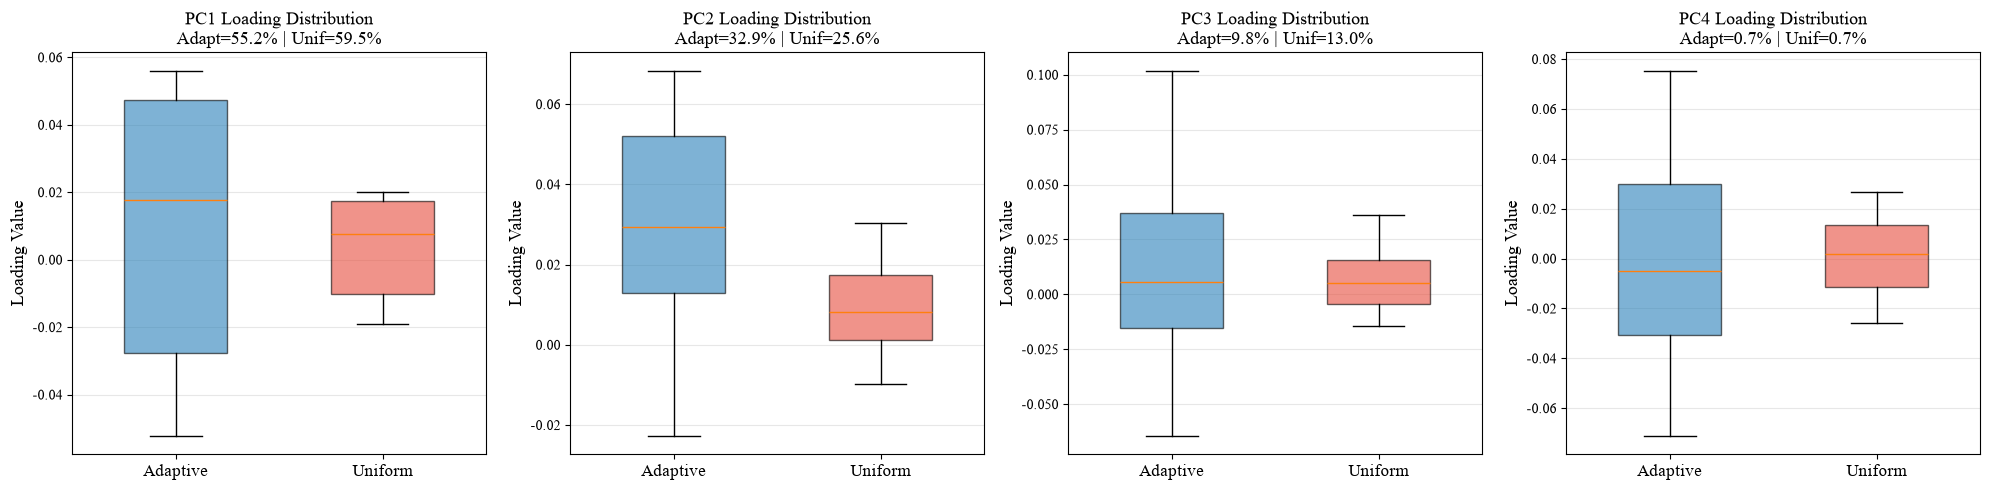


Loading Distribution Summary — All PCs

--- Adaptive ---
PC1      55.2%   0.009496   0.037994   0.108328  -0.2928  -1.4279   0.0390
PC2      32.9%   0.029219   0.026077   0.091107  -0.2625  -0.9797   0.0144
PC3       9.8%   0.010822   0.037638   0.166352   0.3441  -0.6461   0.0367
PC4       0.7%  -0.000958   0.039151   0.146519   0.1680  -1.0112   0.0257

--- Uniform ---
PC1      59.5%   0.003908   0.013696   0.038980  -0.3007  -1.5221   0.3447
PC2      25.6%   0.009167   0.010900   0.040129   0.1493  -0.9599   0.2558
PC3      13.0%   0.006607   0.012617   0.050340   0.4184  -0.8486   0.2471
PC4       0.7%   0.000636   0.014228   0.052541  -0.1611  -1.1669   0.1610
✅ Loading statistics done


In [3]:
# ==================== PCA 载荷统计 + 箱型图对比 ====================
import os
import pyproj; pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')
from scipy.spatial.distance import cdist
from scipy.stats import skew, kurtosis

def moran_i(values, coords):
    """计算 Moran's I 空间自相关指数"""
    n = len(values)
    z = values - np.mean(values)
    W = 1.0 / (1.0 + cdist(coords, coords))
    np.fill_diagonal(W, 0)
    W_sum = np.sum(W)
    if W_sum == 0:
        return np.nan
    return (n / W_sum) * (np.sum(W * np.outer(z, z)) / np.sum(z**2))

mi_label = "Moran's I"
N_PCS = 4  # 分析前 4 个主成分

# ==================== 加载网格中心坐标 ====================
mesh_adapt = pd.read_csv(r'c:\KAN-OLS-SHF\output\model\mesh\quadtree_mesh.csv')
mesh_uniform = pd.read_csv(r'c:\KAN-OLS-SHF\output\model\mesh\normal_mesh_centers.csv')

# ==================== 两个数据集分别 PCA ====================
results_loadings = {}
results_stats = []

for idx, name in enumerate(names):
    X = datasets[name]
    scaler = StandardThenMinMaxScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=N_PCS)
    pca.fit(X_scaled)
    loadings = pca.components_  # (N_PCS, n_features)
    
    if idx == 0:  # Adaptive
        n_match = min(len(mesh_adapt), loadings.shape[1])
        gx = mesh_adapt['center_x'].values[:n_match]
        gy = mesh_adapt['center_y'].values[:n_match]
        label = 'Adaptive'
    else:  # Uniform
        n_match = min(len(mesh_uniform), loadings.shape[1])
        gx = mesh_uniform['center_lon'].values[:n_match]
        gy = mesh_uniform['center_lat'].values[:n_match]
        label = 'Uniform'
    
    coords = np.column_stack([gx, gy])
    
    print(f'\n{"="*65}')
    print(f'📊 {label} Mesh — Loading Statistics')
    print(f'{"="*65}')
    
    for pc_i in range(N_PCS):
        vals = loadings[pc_i, :n_match]
        mi = moran_i(vals, coords)
        print(f'\n  PC{pc_i+1} (var={pca.explained_variance_ratio_[pc_i]*100:.1f}%):')
        print(f'    Mean={np.mean(vals):.6f}  Std={np.std(vals):.6f}  Var={np.var(vals):.6f}')
        print(f'    Min={np.min(vals):.6f}  Max={np.max(vals):.6f}  Range={np.ptp(vals):.6f}')
        print(f'    Skewness={skew(vals):.4f}  Kurtosis={kurtosis(vals):.4f}')
        print(f'    {mi_label}={mi:.4f}')
        
        results_stats.append({
            'Mesh': label, 'PC': f'PC{pc_i+1}',
            'VarExplained': pca.explained_variance_ratio_[pc_i] * 100,
            'Mean': np.mean(vals), 'Std': np.std(vals), 'Var': np.var(vals),
            'Min': np.min(vals), 'Max': np.max(vals), 'Range': np.ptp(vals),
            'Skewness': skew(vals), 'Kurtosis': kurtosis(vals),
            'MoranI': mi
        })
    
    results_loadings[label] = {
        'loadings': loadings[:, :n_match],
        'pca': pca
    }

# ==================== 箱型图对比 ====================
fig, axes = plt.subplots(1, N_PCS, figsize=(5 * N_PCS, 5))
colors_mesh = {'Adaptive': '#2980b9', 'Uniform': '#e74c3c'}

for pc_i in range(N_PCS):
    ax = axes[pc_i]
    data_to_plot = []
    positions = []
    labels_pos = []
    
    for j, label in enumerate(['Adaptive', 'Uniform']):
        vals = results_loadings[label]['loadings'][pc_i]
        data_to_plot.append(vals)
        positions.append(j + 1)
        labels_pos.append(j + 1)
    
    bp = ax.boxplot(data_to_plot, positions=positions, widths=0.5,
                     patch_artist=True, showfliers=True, flierprops={'marker': '.', 'alpha': 0.3})
    for patch, label in zip(bp['boxes'], ['Adaptive', 'Uniform']):
        patch.set_facecolor(colors_mesh[label])
        patch.set_alpha(0.6)
    
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Adaptive', 'Uniform'], fontsize=12)
    ax.set_ylabel('Loading Value', fontsize=13)
    
    # 标题含解释方差
    var_adapt = results_loadings['Adaptive']['pca'].explained_variance_ratio_[pc_i] * 100
    var_uniform = results_loadings['Uniform']['pca'].explained_variance_ratio_[pc_i] * 100
    ax.set_title(f'PC{pc_i+1} Loading Distribution\nAdapt={var_adapt:.1f}% | Unif={var_uniform:.1f}%',
                 fontsize=13)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(r'c:\KAN-OLS-SHF\output\pca_loading_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

# ==================== 汇总统计表 ====================
print(f'\n{"="*70}')
print(f'Loading Distribution Summary — All PCs')
print(f'{"="*70}')
header = f'{"PC":<6} {"Var%":>7} {"Mean":>10} {"Std":>10} {"Range":>10} {"Skew":>8} {"Kurt":>8} {"MoranI":>8}'
print(f'\n--- Adaptive ---')
for s in results_stats:
    if s['Mesh'] == 'Adaptive':
        print(f'{s["PC"]:<6} {s["VarExplained"]:>6.1f}% {s["Mean"]:>10.6f} {s["Std"]:>10.6f} {s["Range"]:>10.6f} {s["Skewness"]:>8.4f} {s["Kurtosis"]:>8.4f} {s["MoranI"]:>8.4f}')
print(f'\n--- Uniform ---')
for s in results_stats:
    if s['Mesh'] == 'Uniform':
        print(f'{s["PC"]:<6} {s["VarExplained"]:>6.1f}% {s["Mean"]:>10.6f} {s["Std"]:>10.6f} {s["Range"]:>10.6f} {s["Skewness"]:>8.4f} {s["Kurtosis"]:>8.4f} {s["MoranI"]:>8.4f}')
print(f'{"="*70}')
print('✅ Loading statistics done')


## 3. 自适应网格 — PCA 载荷空间分布 (PC1-PC4)

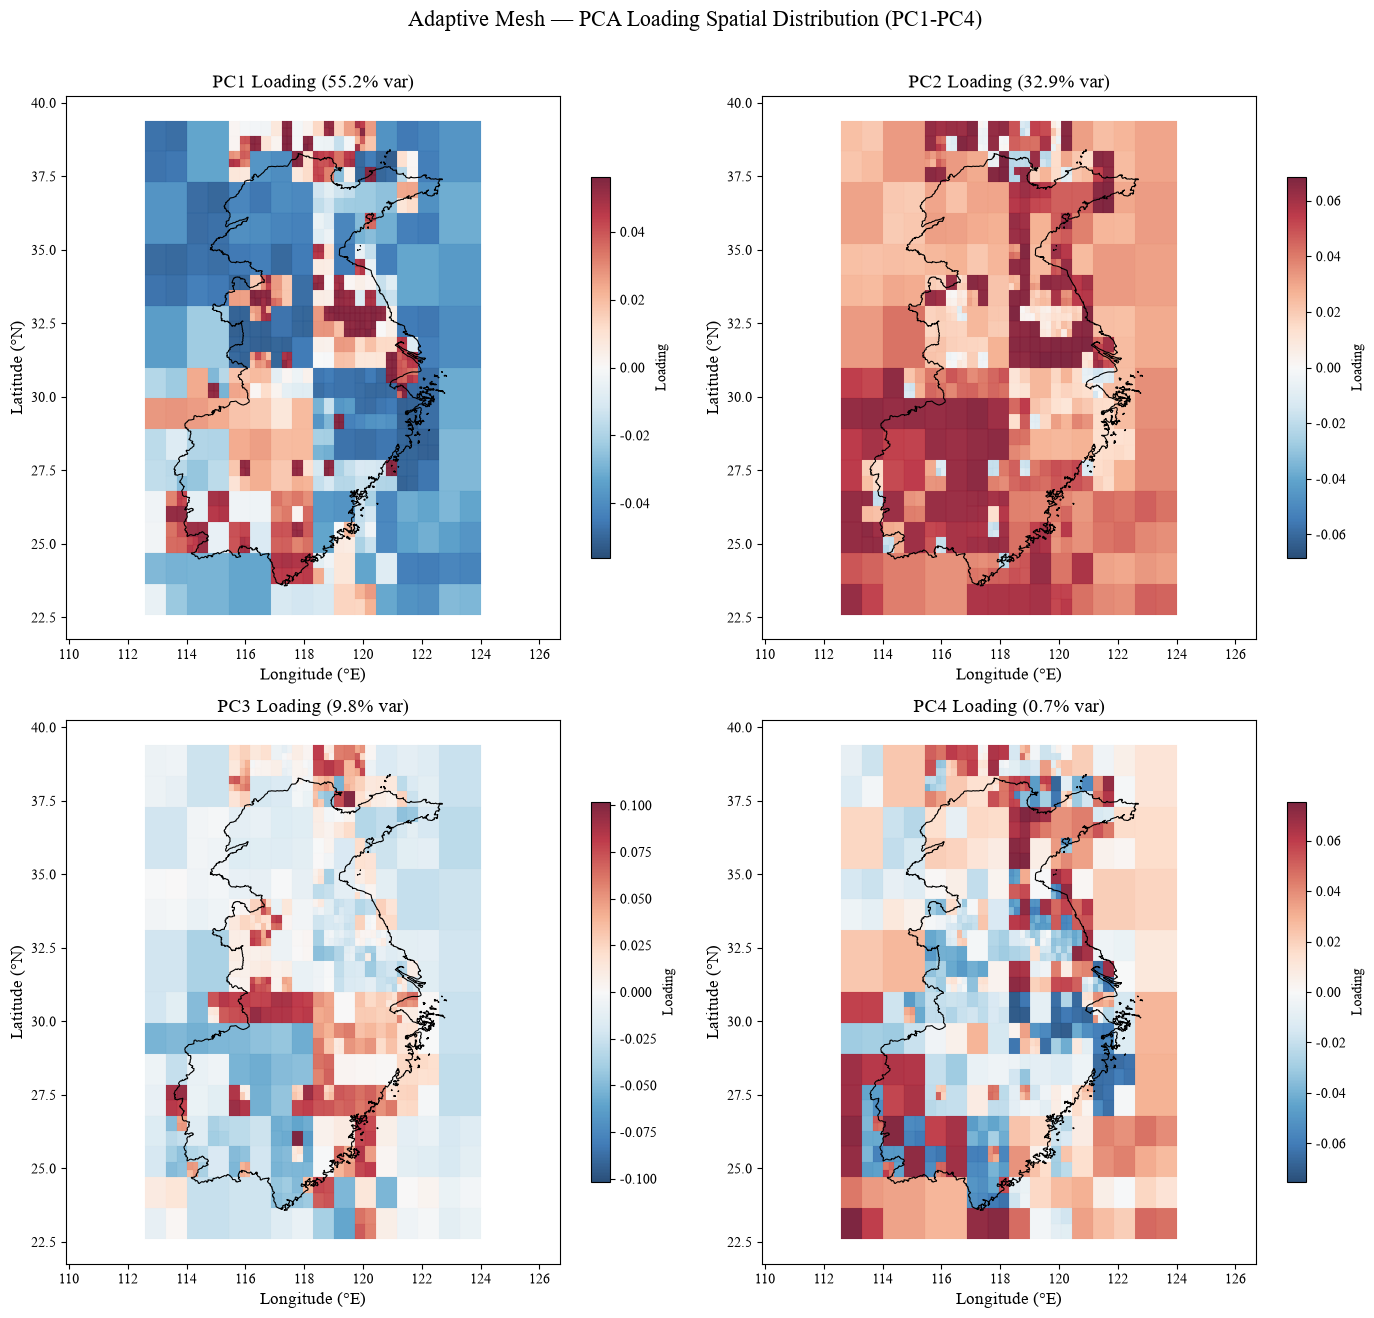

✅ Adaptive PC1-PC4 loading maps done


In [4]:
# ==================== 自适应网格 PC1-PC4 载荷空间分布 ====================
import geopandas as gpd
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

SHAPEFILE = r'c:\KAN-OLS-SHF\data\eastChinaLine.shp'

def simple_bdy(ax, shp):
    if not shp or not os.path.exists(shp): return
    try:
        gdf = gpd.read_file(shp)
        if gdf.crs != 'EPSG:4326': gdf = gdf.to_crs('EPSG:4326')
        for geom in gdf.geometry:
            if geom is None or geom.is_empty: continue
            g = geom.boundary if geom.geom_type in ('Polygon','MultiPolygon') else geom
            if g.geom_type == 'LineString':
                xs,ys = zip(*g.coords); ax.plot(xs,ys,color='black',lw=0.8)
            elif g.geom_type == 'MultiLineString':
                for line in g.geoms: xs,ys=zip(*line.coords); ax.plot(xs,ys,color='black',lw=0.8)
    except: pass

# 确保使用与统计单元格相同的网格数据
mesh_adapt = pd.read_csv(r'c:\KAN-OLS-SHF\output\model\mesh\quadtree_mesh.csv')
n_match = min(len(mesh_adapt), results_loadings['Adaptive']['loadings'].shape[1])
mesh_df = mesh_adapt.iloc[:n_match].copy()
pca_adapt = results_loadings['Adaptive']['pca']
loadings_adapt = results_loadings['Adaptive']['loadings'][:, :n_match]

# 构建矩形 patch 列表（复用，避免重复创建）
rects = [Rectangle((r['xmin'], r['ymin']), r['width'], r['height'])
         for _, r in mesh_df.iterrows()]

fig, axes = plt.subplots(2, 2, figsize=(14, 13))
cmap = plt.cm.RdBu_r

for pc_i, ax in enumerate(axes.flat):
    vals = loadings_adapt[pc_i]
    var_pct = pca_adapt.explained_variance_ratio_[pc_i] * 100
    vmax = np.nanmax(np.abs(vals))
    norm = plt.Normalize(vmin=-vmax, vmax=vmax)
    
    pc = PatchCollection(rects, cmap=cmap, norm=norm, alpha=0.85,
                          edgecolors='face', linewidths=0.1)
    pc.set_array(vals)
    ax.add_collection(pc)
    
    simple_bdy(ax, SHAPEFILE)
    ax.autoscale_view()
    ax.axis('equal')
    ax.set_title(f'PC{pc_i+1} Loading ({var_pct:.1f}% var)', fontsize=14)
    ax.set_xlabel('Longitude (°E)', fontsize=12)
    ax.set_ylabel('Latitude (°N)', fontsize=12)
    plt.colorbar(pc, ax=ax, shrink=0.7, label='Loading')

plt.suptitle('Adaptive Mesh — PCA Loading Spatial Distribution (PC1-PC4)',
             fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(r'c:\KAN-OLS-SHF\output\pca_loading_adaptive_pc1_pc4.png', dpi=300, bbox_inches='tight')
plt.show()
print('✅ Adaptive PC1-PC4 loading maps done')
